# Буткемп, день 10 — книга календарных и межтоварных спредов

Тема дня: собрать из уже построенных спредов один **book** (книгу), задать ему размер простыми
весами и оценить, что комбинация добавляет к лучшему одиночному спреду. Формулировка дня
намеренно отрезвляющая: *«Combining spreads is easy to do and hard to do well. The data can tell you
a lot about risk and very little about which spread is best.»* Сложить P&L нескольких спредов
несложно, а вот понять, добавляет ли книга что-то к лучшему из них, — уже задача про риск, оценку и
капитал. Всё, что ниже, — попытка ответить на это числом, а не верой в диверсификацию.

Данные те же, что в днях 8–9: пикл `~/Downloads/dfs.pickle` с дневными ценами фьючерсов
(`CL`, `HO`, `NG`, `RB` на NYMEX; `GC`, `SI` на COMEX; `ZC`, `ZW`, `ZS`, `ZM`, `ZL` на CBOT). Каждая
буква — контракт по месяцу поставки (`F` — январь, `G` — февраль, `H` — март, `J` — апрель, `K` — май,
дальше по алфавиту), суффикс `_1` — первый по дальности контракт этого месяца. Наборы доступных
месяцев у товаров разные (у `ZW` нет `F_1`, у `GC` месяцы только чётные), поэтому ключи
подбираем по факту наличия, а не по шаблону. Движок (`zscore`, `positions`) взят из дня 8,
построение спредов — из дней 8–9.

In [1]:
import os, pickle, warnings
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.figsize': (11, 3.4), 'figure.dpi': 110, 'axes.grid': True,
                     'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
RNG_SEED = 20251011
DATA = os.path.expanduser('~/Downloads/dfs.pickle')
obj = pickle.load(open(DATA, 'rb'))
print('символов в файле:', len(obj))
print('пример ключей CL.NYMEX:', [k for k in obj['CL.NYMEX'] if not k.startswith('base')][:12])

символов в файле: 44
пример ключей CL.NYMEX: ['F_1', 'F_2', 'G_1', 'G_2', 'H_1', 'H_2', 'J_1', 'J_2', 'K_1', 'K_2', 'M_1', 'M_2']


## Разведка: какие спреды вообще доступны

Прежде чем что-то складывать, посмотрим, из чего выбирать. Сначала соберём ценовые уровни каждого
спреда в **долларах на один комплект** (на одну единицу спреда, а не на один контракт-ногу).

Комплект спреда — это вектор числа контрактов по каждой ноге. Например, крек-спред `3-2-1`
(`crack`) перерабатывает три барреля нефти в два барреля бензина и один баррель печного топлива,
поэтому его комплект — `+2 RB, +1 HO, −3 CL`. Долларовая стоимость комплекта — это сумма
$n_i \cdot M_i \cdot X_i$, где $n_i$ — знак и число контрактов ноги, $M_i$ — размер контракта
(баррелей / бушелей / тройских унций), а $X_i$ — цена в котировке биржи. Именно так мы переводим
каждую ногу в доллары и складываем их в один ряд — «спред в долларах».

In [2]:
def px(sym, key):
    '''Цена Close одного контракта; dropna, чтобы индекс был честный.'''
    return obj[sym][key]['Close'].dropna()

def align(*ss):
    '''Выравниваем ноги по общим дням: спред не определён, если выпала любая нога.'''
    idx = ss[0].index
    for s in ss[1:]:
        idx = idx.intersection(s.index)
    return [s.reindex(idx) for s in ss]

# --- календарные спреды: far - near, в долларах на комплект ---
cal_CL = (px('CL.NYMEX', 'G_1') - px('CL.NYMEX', 'F_1')) * 1000      # $/bbl * 1000 bbl
cal_ZC = (px('ZC.CBOT', 'K_1') - px('ZC.CBOT', 'H_1')) * 5000 * 0.01   # ¢/bu × 0.01 $/¢ × 5000 bu → доллары
cal_NG = (px('NG.NYMEX', 'G_1') - px('NG.NYMEX', 'F_1')) * 10000     # $/MMBtu * 10000
cal_GC = (px('GC.COMEX', 'J_1') - px('GC.COMEX', 'G_1')) * 100       # $/oz * 100 oz

# --- межтоварные спреды ---
RB, HO, CL = align(px('RB.NYMEX', 'F_1'), px('HO.NYMEX', 'F_1'), px('CL.NYMEX', 'F_1'))
crack = 2 * 42000 * RB + 42000 * HO - 3000 * CL                      # 2 RB + 1 HO - 3 CL
ZM, ZL, ZS = align(px('ZM.CBOT', 'F_1'), px('ZL.CBOT', 'F_1'), px('ZS.CBOT', 'F_1'))
crush = 11 * 100 * ZM + 9 * 60000 * ZL * 0.01 - 50000 * ZS * 0.01    # 11 ZM + 9 ZL - 10 ZS
zw, zc = align(px('ZW.CBOT', 'H_1'), px('ZC.CBOT', 'H_1'))
wheat = (zw - zc) * 5000 * 0.01                                      # wheat - corn, ¢ → $
clho = px('CL.NYMEX', 'F_1') * 1000 - px('HO.NYMEX', 'F_1') * 42000 # CL - HO

ALL = pd.DataFrame({'cal_CL': cal_CL, 'cal_ZC': cal_ZC, 'cal_NG': cal_NG, 'cal_GC': cal_GC,
                    'crack': crack, 'crush': crush, 'wheat': wheat, 'CL_HO': clho})
print('дней по каждому спреду (вся история):')
print(ALL.notna().sum().to_string())
print('\nобщих дней 2010+: %d' % len(ALL[ALL.index >= '2010-01-01'].dropna()))
print('\nдолларовое sd по спреду (2010+) — проверка единиц:')
print(ALL[ALL.index >= '2010-01-01'].dropna().std().round(0).to_string())

дней по каждому спреду (вся история):
cal_CL    10324
cal_ZC    13767
cal_NG     8784
cal_GC    12627
crack      9018
crush     13544
wheat     13760
CL_HO      9889

общих дней 2010+: 3738

долларовое sd по спреду (2010+) — проверка единиц:
cal_CL     1399.0
cal_ZC     1307.0
cal_NG     1998.0
cal_GC     1780.0
crack     18372.0
crush     20436.0
wheat      3270.0
CL_HO      9890.0


Границы рядов совпадают не идеально: самый длинный ряд (`cal_ZC`, `wheat`) начинается в 1970-х, а
`cal_NG` — только с 1990-х, потому что данные по природному газу короче. Мы ограничиваем анализ
2010 годом: к этому моменту все восемь спредов уже торгуются, и общее окно получается достаточно
длинным (около 3740 общих дней), чтобы говорить о Sharpe и корреляциях, а не о шуме одного года.
Период содержит и сланцевый бум в нефти, и эпидемию 2020 года, и зерновой шок 2022-го — то есть
несколько разных режимов, что для книги на риск только полезно.

Дальше считаем корреляции доходностей спредов, без них сравнение было бы бессмысленным.
Именно доходностей (разностей долларовых уровней), а не самих уровней: уровни разных товаров
несопоставимы по единицам, а их корреляция отражала бы общий тренд, а не сходство движения.

In [3]:
CAL = ['cal_CL', 'cal_ZC', 'cal_NG', 'cal_GC']
INTER = ['crack', 'crush', 'wheat', 'CL_HO']
W8 = ALL[ALL.index >= '2010-01-01'].dropna()
R8 = W8.diff().dropna()
C8 = R8.corr()
print('n = %d общих дней, %s .. %s' % (len(W8), W8.index.min().date(), W8.index.max().date()))
display(C8.round(2))

def mean_abs_corr(names):
    return np.mean([abs(C8.loc[names[i], names[j]])
                    for i in range(len(names)) for j in range(i + 1, len(names))])

print('средняя |corr| внутри календарных : %.3f' % mean_abs_corr(CAL))
print('средняя |corr| внутри межтоварных: %.3f' % mean_abs_corr(INTER))
print('средняя |corr| календарные x межтоварные: %.3f' % np.mean(
    [abs(C8.loc[a, b]) for a in CAL for b in INTER]))

n = 3738 общих дней, 2010-01-04 .. 2025-03-04


,cal_CL,cal_ZC,cal_NG,cal_GC,crack,crush,wheat,CL_HO
cal_CL,1.00,-0.00,0.01,0.00,0.23,-0.02,-0.02,-0.16
cal_ZC,-0.00,1.00,0.00,-0.01,-0.01,0.01,0.25,0.02
cal_NG,0.01,0.00,1.00,-0.00,-0.00,-0.02,-0.00,-0.01
cal_GC,0.00,-0.01,-0.00,1.00,0.00,0.00,0.02,-0.00
crack,0.23,-0.01,-0.00,0.00,1.00,0.07,0.01,-0.80
crush,-0.02,0.01,-0.02,0.00,0.07,1.00,-0.00,-0.08
wheat,-0.02,0.25,-0.00,0.02,0.01,-0.00,1.00,0.01
CL_HO,-0.16,0.02,-0.01,-0.00,-0.80,-0.08,0.01,1.00


средняя |corr| внутри календарных : 0.004
средняя |corr| внутри межтоварных: 0.161
средняя |corr| календарные x межтоварные: 0.049


Корреляции сложились в резкую картину. Внутри календарных спредов средняя $|\rho| \approx 0.004$ —
это фактически ноль: `cal_CL`, `cal_ZC`, `cal_NG`, `cal_GC` живут в разных товарах, и их кривые
срочности не связаны. Календарные против межтоварных — тоже почти ноль ($|\rho| \approx 0.05$). А
вот **внутри межтоварных** $|\rho| \approx 0.16$ — заметно выше, и это не случайность: там сидят две
структурные пары. Первая — `cal_ZC` ↔ `wheat` c $\rho=0.25$: пшеница и кукуруза конкурируют за одни
и те же посевные площади и часто идут вместе. Вторая, гораздо более громкая, — `crack` ↔ `CL-HO` c
$\rho=-0.80$: обе конструкции — про переработку нефти, и неудивительно, что они сильно антикоррелируют.
Это ровно тот случай, о котором предупреждает слайд 7: две позиции с $\rho=-0.80$ — это **одна и та
же экономика**, и считать их независимыми источниками дохода нельзя. Поэтому в книгу берём только
одну из пары: `crack` (как более каноничную конструкцию), а `CL-HO` оставляем в стороне — она нужна
только для того, чтобы показать этот факт.

Остальные корреляции почти нулевые — это и есть обещание диверсификации. Но помним установку дня:
данные много говорят о **риске** и почти ничего — о том, какой спред лучше.

## Как измеряется одиночный спред: движок дня 8

Прежде чем строить книгу, зафиксируем измеритель — иначе сравнивать будет не с чем. Движок тот же,
что в дне 8, и построен на z-score с гистерезисом: спред нормируется скользящим средним и стандартным
отклонением за окно $w$ дней,

$$z_t = \frac{S_t - \overline{S}_{t-w:t}}{\mathrm{sd}(S_{t-w:t})},$$

а позиция — это знак отклонения с зоной нечувствительности: входим, когда $|z|>2$, выходим, когда
$|z|$ возвращается к $0.5$, между порогами держим состояние без изменений. Размер позиции в единицах
спреда задаётся равным риском: `units = floor(risk / vol)`, где `vol` — скользящая долларовая
волатильность **самого спреда** (`S.diff().rolling(vw).std()`). Доллар-волатильность берётся на данных
**до текущего дня** (окно с правым краем), поэтому будущего в размере нет. P&L дня — это вчерашняя
позиция на сегодняшнее изменение минус издержки за изменение позиции:

$$\text{PnL}_t = \underbrace{h_{t-1}\,\Delta S_t}_{\text{gross}} - \underbrace{|h_t - h_{t-1}|\cdot c}_{\text{cost}},\qquad h_t = \text{pos}_t \cdot \text{units}_t .$$

Знак ловится противоположно отклонению: если спред ушёл выше среднего, мы ставим на его возврат вниз
(короткая позиция). Издержки $c$ — это стоимость **одной стороны** на комплект спреда; полный круг
(вход и выход) стоит $2c$. Для комплекта `cal_ZC` это один контракт по каждой из двух ног, то есть
2 стороны по \$5 → $c=\$10$; в коде это `$5/контракт/сторона × 2 ноги`. Для `crack` ног три и суммарно
6 контрактов → $c=\$30$; для `crush` 30 контрактов → $c=\$150$. Ставка \$5 за контракт за сторону —
это иллюстративный уровень для ликвидных энергетических и зерновых фьючерсов (биржевой сбор плюс
половинка спреда); важно, что это **не** round-trip, иначе издержки удвоятся, как это случилось в
ловушке дня 9.

In [4]:
# движок дня 8: те же zscore и positions, плюс долларовый портфельный вариант
def zscore(s, w):
    return (s - s.rolling(w).mean()) / s.rolling(w).std()

def positions(z, z_in=2.0, z_out=0.5):
    state, out, zv = 0, np.zeros(len(z)), z.values
    for i in range(len(zv)):
        if np.isnan(zv[i]):
            out[i] = 0; continue
        if state == 0:
            if zv[i] > z_in:  state = -1
            elif zv[i] < -z_in: state = 1
        elif state == 1:
            if zv[i] > -z_out: state = 0
        elif state == -1:
            if zv[i] < z_out: state = 0
        out[i] = state
    return pd.Series(out, index=z.index)

def zscore_df(S, w):  return pd.DataFrame({c: zscore(S[c], w) for c in S.columns})
def pos_df(Z):        return pd.DataFrame({c: positions(Z[c]) for c in Z.columns})

def sharpe(x):
    x = x.dropna()
    return x.mean() / x.std() * np.sqrt(252) if x.std() > 0 else np.nan

def sharpe_ci(sr, years, conf=0.90):
    sd = np.sqrt((1 + sr**2 / 504) / years)
    zq = norm.ppf((1 + conf) / 2)
    return sr - zq * sd, sr + zq * sd, sd
print('движок дня 8 готов; zscore/positions по колонкам через *_df-обёртки')

движок дня 8 готов; zscore/positions по колонкам через *_df-обёртки


## Пункт 1. The inputs — что именно кладём в книгу

Правило дня: sleeves определяются до взгляда на P&L. Иначе соблазн
велик — посмотреть, какой спред в плюсе, и назвать его «ядром книги». Мы делим вход на два sleeve’а
по экономическому смыслу, а не по результату:

- **calendar sleeve** (`cal_CL` и `cal_ZC`) — ставки на форму кривой срочности одного товара. Это не
  прогноз цены нефти или кукурузы, а ставка на то, как расположены контракты вдоль кривой.
- **inter-commodity sleeve** (`crack` и `crush`) — ставки на относительную ценность двух товаров,
  связанных технологически. `crack` — маржа переработки нефти в бензин и печное топливо; `crush` —
  маржа переработки сои в масло и шрот.

Из выданных рядов в книгу не входят `wheat` и `CL_HO`: `wheat` коррелирует с `cal_ZC`
($\rho \approx 0.25$ — та же кукурузная история и конкуренция за посевные площади), а `CL_HO`
антикоррелирован с `crack` ($\rho=-0.80$) и дублирует его экономику (см. разведку).

Итого четыре спреда: два календарных, два межтоварных. Каждый — один ряд в долларах на комплект;
комплект — вектор числа контрактов по ногам, заданный до всякого бэктеста.

| спред | sleeve | ноги (контракты на комплект) | как считается в долларах |
|---|---|---|---|
| `cal_CL` | calendar | $-1$ `CL F_1`, $+1$ `CL G_1` | январь−февраль нефти; \$/bbl $\times 1000$ |
| `cal_ZC` | calendar | $-1$ `ZC H_1`, $+1$ `ZC K_1` | март−май кукурузы; ¢/bu $\times 0.01 \times 5000$ |
| `crack` | inter | $+2$ `RB F_1`, $+1$ `HO F_1`, $-3$ `CL F_1` | нефтепродукты $\times 42000$, нефть $\times 1000$ |
| `crush` | inter | $+11$ `ZM F_1`, $+9$ `ZL F_1`, $-10$ `ZS F_1` | шрот $\times 100$ (\$/тонна), масло $\times 60000$ фунтов (¢→\$ $\times 0.01$), соя $\times 5000$ бушелей (¢→\$ $\times 0.01$) |

Оба календарных спреда построены **far − near**, то есть положительный уровень означает contango
(дальний дороже ближнего, рынок платит за хранение), отрицательный — backwardation. Знак самой
торговли движок выводит из z-score: мы не спорим с направлением, мы торгуем возврат к среднему.

In [5]:
BOOK = ['cal_CL', 'cal_ZC', 'crack', 'crush']          # рукава заданы по смыслу, не по P&L
SLEEVE = {'cal_CL': 'calendar', 'cal_ZC': 'calendar', 'crack': 'inter', 'crush': 'inter'}

# комплект: контрактов на 1 единицу спреда (используется и в leg table далее)
BUNDLE = {'cal_CL': 2, 'cal_ZC': 2, 'crack': 6, 'crush': 30}   # число контрактов-ног в комплекте
COST1 = {c: 5.0 * BUNDLE[c] for c in BOOK}                     # $5/контракт/СТОРОНА; круг = 2*COST1

S = ALL[BOOK][ALL.index >= '2010-01-01'].dropna()
print('книга: %d общих дней, %s .. %s' % (len(S), S.index.min().date(), S.index.max().date()))
print('издержки одной стороны на комплект:', COST1, ' (полный круг = 2x)')
print('карта рукавов:', SLEEVE)

книга: 3738 общих дней, 2010-01-04 .. 2025-03-04
издержки одной стороны на комплект: {'cal_CL': 10.0, 'cal_ZC': 10.0, 'crack': 30.0, 'crush': 150.0}  (полный круг = 2x)
карта рукавов: {'cal_CL': 'calendar', 'cal_ZC': 'calendar', 'crack': 'inter', 'crush': 'inter'}


### Гипотеза дня и её проверка

Рабочая гипотеза: *если корреляции доходностей спредов близки к нулю, то комбинация
четырёх спредов при равном риске даст Sharpe выше, чем у каждого по отдельности, потому что
некоррелированные компоненты складываются по риску, а не по доходности.* Проверяем её по двум числам: (а) средняя $\rho$ книги и предел диверсификации $1/\sqrt{\rho}$; (б) фактические
Sharpe одиночных спредов и книги после издержек. Первое отвечает на вопрос «сколько риска книга
экономит», второе — «превращается ли эта экономия в доходность». Гипотеза подтверждается, только если
верны оба, и именно второй пункт, как мы увидим, ломается.

In [6]:
RISK_USD = 10000.0          # риск-бюджет на один спред в день, $
W_Z, W_VOL = 60, 60         # окна z-score и долларовой волатильности

def run_book(S, risk_usd=RISK_USD, cost1=None, w=W_Z, vw=W_VOL, shift=True):
    'Портфельный движок: одна позиция в единицах спреда на колонку, P&L суммируется.'
    cost1 = pd.Series(COST1) if cost1 is None else cost1
    vol = S.diff().rolling(vw).std()                 # $ vol per unit, up to day t
    units = np.floor(risk_usd / vol)
    held = pos_df(zscore_df(S, w)) * units
    pnl = (held.shift(1) if shift else held) * S.diff()
    cst = held.diff().abs() * cost1
    return held, pnl, cst

held, pnl, cost = run_book(S)
net = pnl - cost                                   # P&L net издержек, по колонкам

rows = []
for c in BOOK:
    rows.append(dict(спред=c, sleeve=SLEEVE[c], Sharpe=round(sharpe(net[c]), 2),
                     passive=round(sharpe(S[c].diff()), 2),
                     PnL=f"${net[c].sum():,.0f}", издержки=f"${cost[c].sum():,.0f}"))
display(pd.DataFrame(rows))

,спред,sleeve,Sharpe,passive,PnL,издержки
0,cal_CL,calendar,0.36,0.04,"$2,944,830","$272,980"
1,cal_ZC,calendar,0.35,0.00,"$4,275,858","$706,330"
2,crack,inter,0.22,0.06,"$403,844","$28,710"
3,crush,inter,0.09,0.04,"$166,593","$171,300"


Одиночные Sharpe после издержек лежат в диапазоне от
$\approx 0.1$ до $\approx 0.36$: `cal_CL` и `cal_ZC` около $0.35$, `crack` $0.22$, `crush` $0.09$.
Это скромные числа — при интервале шириной больше единицы (пункт 6) ни одно из них не отделяется
надёжно от нуля, и уж точно ни одно не тянет на edge.

В таблице отдельно показан Sharpe пассивного удержания (buy & hold — дневное изменение долларовой
цены спреда без всякой стратегии): $+0.04$, $0.00$, $+0.06$, $+0.04$ — около нуля у всех. Именно эту
меру, а не движок, имеют в виду нулевые Sharpe из разведки; слайд же требует движок с
z-score и юнитами, и все сравнения дальше — движковые. Разница между пассивным $0.04$ и движковым
$0.36$ у `cal_CL` объясняется работой mean-reversion фильтра на ряду, который сам по
себе не растёт; насколько она настоящая — покажет чистка роллов в пункте 6.

Отдельно про units: они различаются у спредов на порядки, и это
корректно. Дневная долларовая волатильность комплекта `cal_CL` в среднем около \$252, а `cal_ZC` —
около \$195: тот же порядок, но комплект кукурузного спреда дёшев, и чтобы набрать бюджет \$10\,000,
нужно ~333 юнита против ~174 у `cal_CL`. Ключ к этому — единицы котировки: CBOT котирует кукурузу,
соевые бобы и масло в центах, и если забыть перевести ¢ в \$, ряд раздувается в сто раз, `vol`
становится \$19\,500, `units` падает до трёх, и спред молча несёт в сто раз меньше риска, чем
бюджет, — equal-risk ломается незаметно. Именно поэтому выше мы печатаем долларовое стандартное
отклонение каждого ряда: ~\$1.3\,k у кукурузного календарного спреда и ~\$20\,k у крека с крашем —
естественные масштабы их товаров.

## Пункт 2. Exposure — leg table, нетто-позиция и маржа

Пока модель считала P&L, но в реальности брокер видит не «спреды», а **контракты по ногам**.
Слайды 9–10 показывают механизм: позиции в спредах нужно разложить по ногам, сложить и посмотреть на
нетто-позицию. Если две ноги разных спредов стоят в одном и том же инструменте с противоположными
знаками, они частично гасят друг друга, и издержки на них платить дважды не нужно.

Разложим книгу на ноги на три даты, где все четыре спреда реально держат ненулевой размер. Для `crack` шесть
комплектных контрактов означают `+2u` бензина, `+u` печного топлива и `−3u` нефти.

In [7]:
# разложение комплекта на ноги: {инструмент: контрактов на 1 единицу спреда}
def spread_legs(c, u):
    if c == 'cal_CL': return {'CL F': -u, 'CL G': +u}
    if c == 'cal_ZC': return {'ZC H': -u, 'ZC K': +u}
    if c == 'crack':  return {'RB F': 2 * u, 'HO F': +u, 'CL F': -3 * u}
    if c == 'crush':  return {'ZM F': 11 * u, 'ZL F': 9 * u, 'ZS F': -10 * u}

UM = np.floor(RISK_USD / S.diff().rolling(W_VOL).std())     # units по каждому спреду каждый день

def leg_net(dt):
    u = {c: UM.loc[dt, c] for c in BOOK}
    gross, netd = 0, {}
    for c in BOOK:
        lg = spread_legs(c, u[c])
        gross += sum(abs(v) for v in lg.values())
        for k, v in lg.items():
            netd[k] = netd.get(k, 0) + v
    return u, netd, gross, sum(abs(v) for v in netd.values())

for dt in [pd.Timestamp('2012-10-17'), pd.Timestamp('2017-10-03'), pd.Timestamp('2025-03-04')]:
    u, netd, gross, netabs = leg_net(dt)
    print('%s  units=%s' % (dt.date(), {c: int(u[c]) for c in BOOK}))
    print('          нетто-ноги=%s' % {k: int(v) for k, v in netd.items()})
    print('          gross=%d net=%d saving=%.0f%%' % (gross, netabs, (1 - netabs / gross) * 100))

2012-10-17  units={'cal_CL': 349, 'cal_ZC': 179, 'crack': 4, 'crush': 7}
          нетто-ноги={'CL F': -361, 'CL G': 349, 'ZC H': -179, 'ZC K': 179, 'RB F': 8, 'HO F': 4, 'ZM F': 77, 'ZL F': 63, 'ZS F': -70}
          gross=1290 net=1290 saving=0%
2017-10-03  units={'cal_CL': 296, 'cal_ZC': 816, 'crack': 10, 'crush': 13}
          нетто-ноги={'CL F': -326, 'CL G': 296, 'ZC H': -816, 'ZC K': 816, 'RB F': 20, 'HO F': 10, 'ZM F': 143, 'ZL F': 117, 'ZS F': -130}
          gross=2674 net=2674 saving=0%
2025-03-04  units={'cal_CL': 7, 'cal_ZC': 307, 'crack': 5, 'crush': 3}
          нетто-ноги={'CL F': -22, 'CL G': 7, 'ZC H': -307, 'ZC K': 307, 'RB F': 10, 'HO F': 5, 'ZM F': 33, 'ZL F': 27, 'ZS F': -30}
          gross=748 net=748 saving=0%


Суммирование по ногам ничего не сэкономило: `gross = net` на всех датах. Причина прозрачна — все четыре спреда построены на
**разных** контрактах. Даже там, где совпадает товар (нефть `CL F` есть и в `cal_CL`, и в `crack`),
знаки совпадают, и нетто-позиция — это сумма, а не разность: `cal_CL` коротка по `CL F_1` (он у неё
near), и `crack` тоже коротка по `CL F_1` (в нём `CL` — сырьё, а спред строится как продукт минус
сырьё). Ноги не гасятся, а складываются — значит, издержки платятся полностью, и никакого
«бесплатного» уменьшения позиции книга не даёт.

Экономия неттинга появляется только тогда, когда общая нога двух спредов стоит с противоположными
знаками. Учебный пример из слайда: `crack` (`+2 RB, +1 HO, −3 CL`) плюс `CL-HO` (`+1 CL, −1 HO`).

In [8]:
# иллюстрация слайда: crack + CL-HO, по 1 единице каждого
g_crack, g_clho = {'RB F': 2, 'HO F': 1, 'CL F': -3}, {'CL F': 1, 'HO F': -1}
gross = sum(abs(v) for v in list(g_crack.values()) + list(g_clho.values()))
netd = {}
for d in (g_crack, g_clho):
    for k, v in d.items():
        netd[k] = netd.get(k, 0) + v
netabs = sum(abs(v) for v in netd.values())
print('crack(2RB,1HO,-3CL) + CL-HO(1CL,-1HO): gross=%d, нетто=%s=%d, saving=%.0f%%' % (
    gross, {k: v for k, v in netd.items()}, netabs, (1 - netabs / gross) * 100))
print('HO гасится полностью, а три коротких CL и один длинный складываются в общую короткую -2: экономия 50%')
print('слайд: 22 контракта -> 12, экономия 45% — тот же эффект, но на более широкой сумме')

crack(2RB,1HO,-3CL) + CL-HO(1CL,-1HO): gross=8, нетто={'RB F': 2, 'HO F': 0, 'CL F': -2}=4, saving=50%
HO гасится полностью, а три коротких CL и один длинный складываются в общую короткую -2: экономия 50%
слайд: 22 контракта -> 12, экономия 45% — тот же эффект, но на более широкой сумме


Экономия здесь — 50\% (HO схлопывается полностью, а позиции в нефти складываются в общую короткую позицию
из двух контрактов). В широкой корзине слайда получалось 45\%. Смысл один: неттинг работает там, где
ноги пересекаются и противонаправлены. В нашей книге все ноги разнонаправлены по товарам, поэтому
экономии нет — и это фиксируем как факт.

### Margin под заявленным правилом

Маржа у брокера берётся не с P&L, а с контрактов на ногах, и биржи дают **offset-credit**: если две
ноги внутри одного комплекса стоят в противоположные стороны, требуемая маржа меньше суммы. Заявим
прозрачное правило: маржа по каждой ноге — фиксированная долларовая ставка на контракт (SPAN-подобный
прокси), а на накопленные ноги одного комплекса даём 50\% зачёт, поскольку и `crack`, и `crush` —
внутренне хеджированные. Ставки — округлённые биржевые уровни для ликвидных контрактов: нефть
\$6\,000, бензин \$6\,500, печное \$7\,000 за контракт, кукуруза \$1\,500, соя/масло/шрот
\$2\,000–2\,800.

In [9]:
MARGIN_RATE = {'CL F': 6000, 'CL G': 6000, 'ZC H': 1500, 'ZC K': 1500,
               'RB F': 6500, 'HO F': 7000, 'ZM F': 2200, 'ZL F': 2000, 'ZS F': 2800}
OFFSET = 0.50     # offset-credit внутри комплекса

mrows = []
for dt in [pd.Timestamp('2017-10-03'), pd.Timestamp('2025-03-04')]:
    u, netd, gross, netabs = leg_net(dt)
    net_m = sum(abs(v) * MARGIN_RATE[k] for k, v in netd.items())   # маржа на нетто-ногах
    mrows.append(dict(дата=str(dt.date()), net_margin=f"${net_m:,.0f}",
                      margin_after_offset=f"${net_m * OFFSET:,.0f}"))
display(pd.DataFrame(mrows))

MPU = {'cal_CL': 12000, 'cal_ZC': 3000, 'crack': 38000, 'crush': 70200}   # $ маржи на комплект
rom = []
for c in BOOK:
    avg_m = (UM[c].abs() * MPU[c]).mean()
    rom.append(dict(спред=c, Sharpe=round(sharpe(net[c]), 2),
                    avgMargin=f"${avg_m:,.0f}",
                    return_on_margin=f"{net[c].mean() / avg_m * 252:.1%}"))
display(pd.DataFrame(rom))
print('RoM = средний дневной P&L / средняя занятая маржа, ×252; offset-credit здесь не давать')

,дата,net_margin,margin_after_offset
0,2017-10-03,"$7,292,600","$3,646,300"
1,2025-03-04,"$1,405,600","$702,800"


,спред,Sharpe,avgMargin,return_on_margin
0,cal_CL,0.36,"$2,093,781",9.6%
1,cal_ZC,0.35,"$997,600",29.4%
2,crack,0.22,"$258,251",10.7%
3,crush,0.09,"$450,479",2.5%


RoM = средний дневной P&L / средняя занятая маржа, ×252; offset-credit здесь не давать


Слайд 24 предупреждает именно об этом: ранжирование по Sharpe и по return-on-margin не совпадает.
По Sharpe лидирует `cal_CL` ($0.36$), но комплект из двух нефтяных ног стоит \$12\,000 маржи, и при
бюджете \$10\,000 книга набирает ~174 комплекта — в среднем \$2.1\,M занятого капитала ради
\$800 дневного дохода (RoM ~10\%). `cal_ZC` при почти том же Sharpe держит вдвое меньше занятого капитала
и даёт RoM ~29\%, а `crush` с худшим Sharpe ($0.09$) — самый дорогой на капитал (RoM ~2.5\%). Порядок
«по риску» и «по капиталу» расходится именно так, как обещает слайд: лучший спред зависит от того,
что мы нормируем; книга эту неоднозначность показывает наглядно.

## Пункт 3. Sizing — как задать размер книги

Размер книги собирается из трёх ручек, которые задают риск, а не доходность.

**Equal risk.** Базовая ручка уже внутри движка: `units = floor(risk / vol)` на спред, где `vol` —
долларовая волатильность **этого** спреда, посчитанная на данных до текущего дня. Наивная ошибка —
взять стандартное отклонение по всей истории (`S.std()`): это заглядывание в будущее, размер позиции
в начале пути будет знать размах всего ряда. Мы этого не делаем: `.rolling(vw).std()` право-выровнен,
то есть использует дни до `t` включительно. Формально это покрывают проверки движка в конце.

**Book vol target.** Идея: книга должна работать с более или менее постоянной волатильностью, а не
раздуваться, когда спреды разволновались. Общий масштаб — `target / trailing_book_vol`, где
`trailing_book_vol` — скользящая волатильность уже **P&L книги**, сверху зажатая в cap, чтобы книга
не улетала на десятки плеч в спокойные периоды. И масштаб, и vol обязаны быть **lagged**
(`.shift(1)`): масштаб сегодняшнего дня не может зависеть от сегодняшнего P&L.

**No-trade band.** `units` меняется каждый день вместе с `vol`, и без ограничения движок дёргается
из-за целочисленного округления и микроизменений vol, платя издержки на каждое лишнее изменение размера. No-trade band
меняет позицию только тогда, когда цель сдвинулась на $\geq N$ единиц от текущей; внутри коридора
держим прежний размер.

**Cap на вклад одного спреда.** Один спред не должен нести больше $1/3$ риска книги. Это
предохранитель от того, что один «шумный» ряд с огромной `vol` перетянет всю книгу.

In [10]:
# (a) equal risk: без band как основной вариант и с no-trade band
def risk_units_with_band(c, band=25):
    pos = positions(zscore(S[c], W_Z)).values
    tgt = np.floor(RISK_USD / S.diff().rolling(W_VOL).std()[c]).fillna(0).values
    out = np.zeros(len(S)); cur_pos, cur_u = 0.0, 0.0
    for i in range(len(S)):
        if pos[i] != cur_pos or abs(tgt[i] - cur_u) >= band:
            cur_pos, cur_u = pos[i], tgt[i]
        out[i] = cur_pos * cur_u
    return pd.Series(out, index=S.index)

def book_from_held(hold_df):
    pnl = hold_df.shift(1) * S.diff()
    cst = hold_df.diff().abs() * pd.Series(COST1)
    return (pnl - cst).sum(axis=1), pnl - cst

def book_cost(hold_df):
    return sum((hold_df[c].diff().abs() * COST1[c]).sum() for c in BOOK)

H_er = pos_df(zscore_df(S[BOOK], W_Z)) * np.floor(RISK_USD / S.diff().rolling(W_VOL).std())
book_er, _ = book_from_held(H_er)
H_band = pd.DataFrame({c: risk_units_with_band(c, 25) for c in BOOK})
book_band, _ = book_from_held(H_band)
print('книга equal risk (без band): Sharpe=%+.2f PnL=$%.0f издержки=$%.0f' % (
    sharpe(book_er), book_er.sum(), book_cost(H_er)))
print('книга equal risk (band=25) : Sharpe=%+.2f PnL=$%.0f издержки=$%.0f' % (
    sharpe(book_band), book_band.sum(), book_cost(H_band)))

книга equal risk (без band): Sharpe=+0.51 PnL=$7791125 издержки=$1179320
книга equal risk (band=25) : Sharpe=+0.56 PnL=$8724531 издержки=$1116870


In [11]:
# (b) book vol target поверх книги из (a): lagged, сглаженный, с cap
TARGET_BOOK_VOL = 100000.0
trail_book_vol = book_band.rolling(W_VOL).std().shift(1)     # строго lagged
scale = (TARGET_BOOK_VOL / trail_book_vol).clip(upper=3.0).fillna(0)
book_vt = (book_band * scale).dropna()
print('book vol target: без масштабирования SR=%+.2f  с масштабированием SR=%+.2f' % (
    sharpe(book_band), sharpe(book_vt)))
print('масштаб: средний %.2f, максимальный %.2f (cap=3); дневная вола книги $%.0f -> цель $%.0f' % (
    scale.mean(), scale.max(), book_band.std(), TARGET_BOOK_VOL))

book vol target: без масштабирования SR=+0.56  с масштабированием SR=+0.60
масштаб: средний 2.48, максимальный 3.00 (cap=3); дневная вола книги $66680 -> цель $100000


In [12]:
# (c) вклад риска и cap на один спред: RC_i = w_i (Sigma w)_i / sigma_p, сумма = sigma_p
def risk_contrib(net_df):
    'Вклад в риск для весов равного риска w ~ 1/sigma.'
    sig = net_df.std() * np.sqrt(252)
    w = (1 / sig); w = w / w.sum()
    Cov = net_df.cov() * 252
    sp = np.sqrt(w.values @ Cov.values @ w.values)
    rc = w.values * (Cov.values @ w.values) / sp
    return pd.Series(rc, index=net_df.columns), sp

rc_er, sp_er = risk_contrib(net[BOOK])
sh_ = (rc_er / rc_er.sum())
print('виртуальный equal-risk (w ~ 1/sigma): доли вклада в риск:')
print(sh_.round(3).to_string())
print('максимальная доля = %.2f -> cap 1/3 %s' % (
    sh_.max(), 'не срабатывает' if sh_.max() <= 1/3 else 'срабатывает'))

# вклад реальной книги: RC_i = Cov(PnL_i, book) / sigma_book, сумма = sigma_book
book_net = net.sum(axis=1)
sig_b = book_net.std() * np.sqrt(252)
rc_act = net.apply(lambda col: col.cov(book_net) * 252) / sig_b
print('\nфактические доли вклада в риск книги (вола $%.0f):' % sig_b)
print((rc_act / rc_act.sum()).round(3).to_string())

# cap: итеративно режем units лидера вклада, пока его доля не станет <= 1/3
# (RC по всей истории — демонстрация механизма с look-ahead; ниже trailing-версия без заглядывания)
def cap_units(um_df, cap=1/3, iters=40):
    um = um_df.copy()
    for _ in range(iters):
        h = pos_df(zscore_df(S, W_Z)) * um
        n = h.shift(1) * S.diff() - h.diff().abs() * pd.Series(COST1)
        b = n.sum(axis=1); sb = b.std() * np.sqrt(252)
        sh = n.apply(lambda col: col.cov(b) * 252) / sb
        sh = sh / sh.sum()
        i = sh.idxmax()
        if sh[i] <= cap:
            break
        um[i] = np.floor(um[i] * (cap / sh[i]))
    return um, sh

UM_cap, sh_cap = cap_units(UM)
H_cap = pos_df(zscore_df(S, W_Z)) * UM_cap
net_cap = H_cap.shift(1) * S.diff() - H_cap.diff().abs() * pd.Series(COST1)
print('\nпосле cap доли:', sh_cap.round(3).to_dict())
print('SR книги: без cap %+.2f -> с cap %+.2f (units cal_ZC %.0f -> %.0f)' % (
    sharpe(book_net), sharpe(net_cap.sum(axis=1)), UM['cal_ZC'].mean(), UM_cap['cal_ZC'].mean()))

# trailing-версия cap: RC только по realized P&L до текущего дня, множитель меняется только вперёд
def cap_units_trailing(um_df, cap=1/3, min_hist=250, step=21):
    pos0 = pos_df(zscore_df(S, W_Z))
    mult = pd.DataFrame(1.0, index=S.index, columns=BOOK)
    cur = pd.Series(1.0, index=BOOK)
    for t in range(min_hist, len(S), step):
        h = pos0 * (um_df * mult)
        n = (h.shift(1) * S.diff() - h.diff().abs() * pd.Series(COST1)).iloc[:t]
        b = n.sum(axis=1); sb = b.std() * np.sqrt(252)
        if not np.isfinite(sb) or sb <= 0:
            continue
        sh = n.apply(lambda col: col.cov(b) * 252) / sb
        if not np.isfinite(sh).all() or sh.sum() <= 0:
            continue
        sh = sh / sh.sum(); i = sh.idxmax()
        if sh[i] > cap:
            cur[i] = max(cur[i] * cap / sh[i], 0.05)
            mult.iloc[t:] = cur.values          # правка действует только на будущее
    return pos0 * (um_df * mult)

H_tr = cap_units_trailing(UM)
net_tr = H_tr.shift(1) * S.diff() - H_tr.diff().abs() * pd.Series(COST1)
print('\ntrailing-cap без look-ahead: SR %+.2f против %+.2f у cap по всей истории' % (
    sharpe(net_tr.sum(axis=1)), sharpe(net_cap.sum(axis=1))))
print('разница %+.2f — вклад look-ahead; 0.48 — верхняя граница механизма, в основной результат cap не входит' % (
    sharpe(net_cap.sum(axis=1)) - sharpe(net_tr.sum(axis=1))))


виртуальный equal-risk (w ~ 1/sigma): доли вклада в риск:
cal_CL    0.269
cal_ZC    0.227
crack     0.273
crush     0.231
максимальная доля = 0.27 -> cap 1/3 не срабатывает

фактические доли вклада в риск книги (вола $1032654):
cal_CL    0.305
cal_ZC    0.651
crack     0.028
crush     0.016



после cap доли: {'cal_CL': 0.331, 'cal_ZC': 0.325, 'crack': 0.19, 'crush': 0.154}
SR книги: без cap +0.51 -> с cap +0.48 (units cal_ZC 333 -> 76)



trailing-cap без look-ahead: SR +0.47 против +0.48 у cap по всей истории
разница +0.01 — вклад look-ahead; 0.48 — верхняя граница механизма, в основной результат cap не входит


Три ручки сработали по-разному; с cap вышла отдельная история. На виртуальных equal-risk
весах ($w_i \propto 1/\sigma_i$) вклады почти равны ($0.23$–$0.27$), и cap $1/3$ не ограничивает — ровно
как и должно быть у равного риска. Но реальная книга — не виртуальные веса: `units = floor(risk / vol)`
выравнивает бюджет по 60-дневной скользящей воле, а реализованная вола кукурузного спреда жирнее
хвостами засух 2012-го и 2022-го, и на ней бюджет систематически занижен: в фактических вкладах
`cal_ZC` забирает $0.65$ риска книги. Здесь cap срабатывает: после итеративного урезания units `cal_ZC`
со средних 333 до 76 вклады становятся $0.33/0.33/0.19/0.15$, а Sharpe книги падает с $0.51$ до
$0.48$. Cap ловит расхождение скользящей и реализованной волатильностей.
RC для cap считаем по всей истории, поэтому $0.48$ содержит look-ahead и остаётся верхней границей
механизма; trailing-версия без заглядывания (множитель меняется только вперёд, RC — по realized
P&L до текущего дня) даёт $0.47$ — вывод о работоспособности ручки не меняется, но в основной
результат cap не входит. No-trade band на 25
единиц поднимает Sharpe с $0.51$ до $0.56$ и слегка снижает издержки (\$1\,179\,000 → \$1\,117\,000):
размер позиции «дребезжит» каждый день из-за целочисленного округления, и сглаживание помогает тем,
что книга не отрабатывает микрошум. Для `crack` и `crush` со средними ~7 юнитами band в 25
единиц не срабатывает вовсе — он ограничивает только крупно-юнитные календарные спреды, а размер
межтоварных меняется вместе с сигналом. Book vol target добавляет ещё до $0.60$: средний масштаб около
$2.5$, максимум упирается в cap $3$. Основным вариантом дальше держим equal-risk без band и vol-target —
именно его цифры идут в пункт 4 и в выводы.

## Пункт 4. The book — P&L, корреляции и вклад в риск

Теперь соберём итоговую книгу и посмотрим, что комбинация даёт. Основной вариант — равный риск
без band и без vol-target (самый простой и потому честный вариант); ниже сравним с equal-weight.

In [13]:
netER = net[BOOK]                          # equal-risk (units = floor(risk/vol))
ber = netER.sum(axis=1)                     # P&L книги
# equal weight: одинаковое число единиц спреда на спред (units=1)
H_ew = pos_df(zscore_df(S[BOOK], W_Z))
netEW = H_ew.shift(1) * S[BOOK].diff() - H_ew.diff().abs() * pd.Series(COST1)
bew = netEW.sum(axis=1)

summary = pd.DataFrame({
    'схема': ['equal risk', 'equal weight'],
    'Sharpe': [round(sharpe(ber), 2), round(sharpe(bew), 2)],
    'PnL': [f"${ber.sum():,.0f}", f"${bew.sum():,.0f}"],
    'maxDD': [f"${(ber.cumsum()-ber.cumsum().cummax()).min():,.0f}",
              f"${(bew.cumsum()-bew.cumsum().cummax()).min():,.0f}"]})
display(summary)
best_single = max(sharpe(netER[c]) for c in BOOK)
print('лучший одиночный Sharpe книги: %+.2f   книга ER: %+.2f   книга EW: %+.2f' % (
    best_single, sharpe(ber), sharpe(bew)))
for nm, cols in [('calendar sleeve', ['cal_CL', 'cal_ZC']),
                 ('inter-commodity sleeve', ['crack', 'crush'])]:
    sl = netER[cols].sum(axis=1)
    print('%-22s SR=%+.2f PnL=$%.0f' % (nm, sharpe(sl), sl.sum()))
turn_er = int(held.diff().abs().sum().sum()); turn_ew = int(H_ew.diff().abs().sum().sum())
print('оборот: ER %d смен позиции (издержки $%.0f), EW %d (издержки $%.0f)' % (
    turn_er, cost.sum().sum(), turn_ew,
    (H_ew.diff().abs() * pd.Series(COST1)).sum().sum()))

,схема,Sharpe,PnL,maxDD
0,equal risk,0.51,"$7,791,125","$-1,865,495"
1,equal weight,0.75,"$463,636","$-51,054"


лучший одиночный Sharpe книги: +0.36   книга ER: +0.51   книга EW: +0.75
calendar sleeve        SR=+0.49 PnL=$7220687
inter-commodity sleeve SR=+0.21 PnL=$570437
оборот: ER 100030 смен позиции (издержки $1179320), EW 519 (издержки $28430)


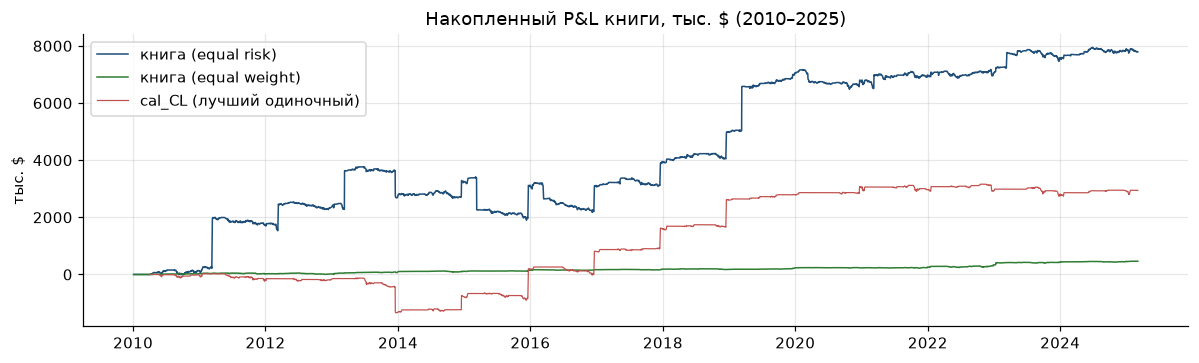

In [14]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(ber.index, ber.cumsum()/1000, lw=1.0, color='#1f4e79', label='книга (equal risk)')
ax.plot(bew.index, bew.cumsum()/1000, lw=1.0, color='#2e7d32', label='книга (equal weight)')
ax.plot(netER.index, netER['cal_CL'].cumsum()/1000, lw=.8,
        color='#c0504d', label='cal_CL (лучший одиночный)')
ax.set_title('Накопленный P&L книги, тыс. \\$ (2010–2025)')
ax.set_ylabel('тыс. \\$'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

In [15]:
Cs = netER.corr()
print('corr P&L спредов книги:')
display(Cs.round(3))
N = len(BOOK)
rho_bar = (Cs.values.sum() - N) / (N * (N - 1))
print('средняя парная корреляция книги rho = %.4f' % rho_bar)
print('предел диверсификации 1/sqrt(rho) = %.2f' % (1 / np.sqrt(rho_bar)))

corr P&L спредов книги:


,cal_CL,cal_ZC,crack,crush
cal_CL,1.000,-0.001,0.192,-0.004
cal_ZC,-0.001,1.000,-0.003,0.005
crack,0.192,-0.003,1.000,0.015
crush,-0.004,0.005,0.015,1.000


средняя парная корреляция книги rho = 0.0340
предел диверсификации 1/sqrt(rho) = 5.42


In [16]:
sig = netER.std() * np.sqrt(252)
Cov = netER.cov() * 252
w = (1 / sig); w = w / w.sum()
sp = np.sqrt(w.values @ Cov.values @ w.values)
rc = pd.Series(w.values * (Cov.values @ w.values) / sp, index=BOOK)
print('доли вклада в риск (сумма = 1):')
print((rc / rc.sum()).round(3).to_string())
print('сумма RC = $%.0f; вола виртуального equal-risk портфеля = $%.0f' % (rc.sum(), sp))

# diversification ratio — ТОЛЬКО на нормированных рядах
Rn = netER / netER.std()
DR = Rn.std().mean() / Rn.mean(axis=1).std()
print('standalone годовая вола ($):', dict(zip(BOOK, sig.round(0))))
print('diversification ratio равнорисовой композиции (нормированные ряды, w ~ 1/sigma) = %.2f' % DR)
print('сумма standalone вол / вола книги = %.2f: это классический DR портфеля с равными весами на' % (
    sig.sum() / (ber.std() * np.sqrt(252))))
print(' долларовых P&L рукавов (равновесного на рукавах, а не равнорисового); оба числа в долларах, «разных единиц» тут нет')

доли вклада в риск (сумма = 1):
cal_CL    0.269
cal_ZC    0.227
crack     0.273
crush     0.231
сумма RC = $113777; вола виртуального equal-risk портфеля = $113777
standalone годовая вола ($): {'cal_CL': 563912.0, 'cal_ZC': 840167.0, 'crack': 128610.0, 'crush': 129626.0}
diversification ratio равнорисовой композиции (нормированные ряды, w ~ 1/sigma) = 1.91
сумма standalone вол / вола книги = 1.61: это классический DR портфеля с равными весами на
 долларовых P&L рукавов (равновесного на рукавах, а не равнорисового); оба числа в долларах, «разных единиц» тут нет


Корреляции P&L внутри книги близки к нулю (средняя $\rho = 0.034$), предел
диверсификации $1/\sqrt{\rho} \approx 5.4$ — то есть по риску книга действительно экономит:
diversification ratio равнорисовой композиции около $1.9$, а сумма standalone вол спредов
примерно в $1.6$ раза больше волатильности книги (классический DR при равных весах на рядах P&L). Сумма risk contributions сходится ровно к волатильности виртуального equal-risk
портфеля (нормированные веса $w \propto 1/\sigma$, \$114\,000), а доли почти равны ($0.23$–$0.27$) —
это проверка формулы. У фактической книги вклады другие: при годовой воле \$1.0\,M на `cal_ZC`
приходится $0.65$ риска, потому что floor(risk / скользящей vol) выравнивает бюджет по спокойным дням,
а реализованную волатильность определяют хвосты (пункт 3, cap).

По доходности картина тоньше. Книга equal-risk даёт Sharpe $0.51$,
а лучший одиночный спред (`cal_CL`, $0.36$) — книга его обходит. Однако книга **equal-weight** даёт
$0.75$ — и вот она обгоняет всё. Выглядит это как «комбинация работает», но прочтение другое: equal-weight держит по одной единице каждого спреда, его годовая вола (~\$42\,k)
в 25 раз меньше, чем у equal-risk (~\$1.0\,M), а оборот примерно в 200 раз реже — EW выигрывает не
«правильными весами», а низкой волей и издержками на несопоставимом риске. При равных долларовых бюджетах equal-risk обгоняет лучший одиночный спред лишь на $0.15$ — и этот зазор статистически незначим:
$SR$ лучшего одиночного ($0.36$) попадает внутрь $90\%$ CI книги $[0.09, 0.93]$ (пункт 6).

Diversification ratio не переносится в Sharpe: он говорит, насколько меньше риск той же суммы
позиций; если компоненты в среднем едва зарабатывают (Sharpe около нуля), уменьшение риска уменьшает
и дисперсию дохода — Sharpe почти не меняется. Именно об этом предупреждает тема дня: данные хорошо
говорят о риске и плохо — о том, какой спред лучший.

## Пункт 5. Шок корреляций и hindsight

### Шок корреляций

Слабый момент любой диверсификации — то, что в кризисе корреляции растут к единице. Слайд 13 задаёт
формулу для портфеля из $N$ равных позиций с постоянной корреляцией $\rho$:

$$\sigma_p = \sigma\sqrt{\frac{1 + (N-1)\rho}{N}}.$$

При $N=10$ и росте $\rho$ от $0.1$ до $0.7$ риск растёт в $\sqrt{(1+9\cdot0.7)/(1+9\cdot0.1)} =
\sqrt{7.3/1.9} \approx 1.96$ раза. Применим ту же логику к нашей книге ($N=4$): насколько вырастет
риск, если сегодняшняя $\rho = 0.034$ поднимется до стрессовых уровней.

In [17]:
for rho_t in [0.1, 0.3, 0.5, 0.7]:
    mult = np.sqrt((1 + (N - 1) * rho_t) / (1 + (N - 1) * rho_bar))
    print('rho %.3f -> %.2f  риск x%.2f  (вола книги $%.0f -> $%.0f)' % (
        rho_bar, rho_t, mult, sp, sp * mult))
print('слайд 13 (N=10, 0.1->0.7): x%.2f' % np.sqrt((1 + 9 * 0.7) / (1 + 9 * 0.1)))

rho 0.034 -> 0.10  риск x1.09  (вола книги $113777 -> $123573)
rho 0.034 -> 0.30  риск x1.31  (вола книги $113777 -> $149392)
rho 0.034 -> 0.50  риск x1.51  (вола книги $113777 -> $171364)
rho 0.034 -> 0.70  риск x1.68  (вола книги $113777 -> $190823)
слайд 13 (N=10, 0.1->0.7): x1.96


Оценка шока чувствительна к числу ног книги: у нас всего четыре спреда, поэтому тот же сдвиг $\rho$ поднимает
риск лишь в $1.09$–$1.68$ раза против $1.96$ на десяти ногах. Это цена малой книги: мало
компонентов — меньше диверсификации, но и меньше «спрятанного» совместного риска. Отдельная ловушка
здесь в том, что по формуле при $N=4$ предел роста риска — не бесконечность, а $\sqrt{4}=2$ (когда
$\rho \to 1$), так что даже полное схлопывание корреляций не страшнее двукратного роста.

### Hindsight: веса, подобранные по всей истории

Слайд 20 формулирует ловушку прямо: если подобрать веса по всей истории (max-Sharpe, где
$w \propto \Sigma^{-1}\mu$), получится красивая кривая — но эта красота надута тем, что веса знали
будущее. В симуляции слайда honest max-Sharpe даёт Sharpe $0.46$, hindsight — $1.28$ (инфляция
$\times2.8$), и hindsight «лучше» равных весов на 58\%, хотя на будущем хуже.

Повторим это на своей книге: сравним (а) веса, подогнанные на **всей** истории, и (б) веса,
пересчитываемые **расширяющимся окном** только на прошлых данных (honest).

In [18]:
# (a) hindsight: max-Sharpe веса по всей истории
mu = netER.mean() * 252
Cov_y = netER.cov() * 252
w_hind = np.linalg.pinv(Cov_y.values) @ mu.values
w_hind = w_hind / np.abs(w_hind).sum()          # нормируем на единичную сумму модулей
h_hind = pd.Series(netER.values @ (w_hind * RISK_USD), index=netER.index)
print('hindsight веса (вся история):', dict(zip(BOOK, w_hind.round(2))))
print('hindsight max-Sharpe книги: SR=%+.2f' % sharpe(h_hind))
print('знаки hindsight весов: все %s (Σ|w| = %.2f) — шортов схема не дала' % (
    'положительны' if (w_hind > 0).all() else 'разные', np.abs(w_hind).sum()))

# (b) honest: expanding-window max-Sharpe, только прошлые данные
MIN = 250
honest = np.full(len(netER), np.nan)
for t in range(MIN, len(netER)):
    R = netER.iloc[:t]
    w_ = np.linalg.pinv((R.cov() * 252).values) @ (R.mean() * 252).values
    w_ = w_ / (np.abs(w_).sum() or 1)
    honest[t] = float(netER.iloc[t].values @ (w_ * RISK_USD))
honest = pd.Series(honest, index=netER.index).dropna()
print('honest expanding max-Sharpe: SR=%+.2f' % sharpe(honest))
print('инфляция hindsight/honest  : x%.2f' % (sharpe(h_hind) / sharpe(honest)))
print('для сравнения: equal risk SR=%+.2f, equal weight SR=%+.2f' % (sharpe(ber), sharpe(bew)))

hindsight веса (вся история): {'cal_CL': np.float64(0.21), 'cal_ZC': np.float64(0.15), 'crack': np.float64(0.42), 'crush': np.float64(0.23)}
hindsight max-Sharpe книги: SR=+0.53
знаки hindsight весов: все положительны (Σ|w| = 1.00) — шортов схема не дала


honest expanding max-Sharpe: SR=+0.09
инфляция hindsight/honest  : x6.10
для сравнения: equal risk SR=+0.51, equal weight SR=+0.75


Инфляция hindsight у нас $\times 6.1$ даже больше, чем в симуляции слайда ($\times 2.8$): на
реальных данных с четырьмя шумными и почти некоррелированными рядами inverse-variance веса — это
классическое переобучение. Hindsight «max-Sharpe» даёт $0.53$, honest — только $0.09$; то есть честно
посчитанная «оптимизация» весов проигрывает даже равному риску ($0.51$) и сильно проигрывает
equal-weight ($0.75$; помня, что вола EW в ~25 раз меньше — это сравнение не на равном риске). Ещё заметнее урок слайда 20 в другом: даже hindsight $0.53$ ниже наивного
равного веса $0.75$ — «знание будущего» не помогло обогнать простую схему. Оптимизация весов
максимизирует прошлое и переносится на будущее плохо; простота на этой задаче не проигрывает.
Отдельно про знаки: hindsight-веса вышли все положительными ($\sum|w_i|=1$) — слайдовая max-Sharpe
схема допускает шорты, но на этих данных $\Sigma^{-1}\mu$ вывел лонг по всем четырём sleeve’ах; это
свойство оценки на короткой шумной истории ($\mu$ у всех четырёх рядов положительный), а не утверждение,
что шорт-ноги не нужны.

## Пункт 6. Judge it — Sharpe с интервалом, число попыток, held-out

Ширина доверительного интервала для Sharpe при $T$ годах:

$$\mathrm{sd}(\widehat{SR}) \approx \sqrt{\frac{1 + SR^2/504}{T}},\qquad
90\%\ \text{CI} = \widehat{SR} \pm 1.645\,\mathrm{sd}.$$

При истинном $SR=1$ и десяти годах это даёт $[0.48, 1.52]$ — интервал шириной больше единицы, то есть
даже настоящий Sharpe днём с огнём не отделить от нуля при таком горизонте. У нас $T\approx15$ лет,
$\mathrm{sd}\approx0.26$ — и этого всё ещё мало, чтобы книга и лучший спред статистически разошлись.

In [19]:
years = (S.index[-1] - S.index[0]).days / 365.25
print('длина истории T=%.1f лет, sd(Sharpe) ~ %.2f' % (years, 1 / np.sqrt(years)))
rows = []
for nm, x in [('book equal-risk', ber), ('book equal-weight', bew),
              ('cal_CL', netER['cal_CL']), ('cal_ZC', netER['cal_ZC']),
              ('crack', netER['crack']), ('crush', netER['crush'])]:
    sr = sharpe(x); lo, hi, sd = sharpe_ci(sr, years)
    rows.append(dict(что=nm, Sharpe=round(sr, 2),
                     CI90=f"[{lo:+.2f}, {hi:+.2f}]", PnL=f"${x.sum():,.0f}"))
display(pd.DataFrame(rows))

длина истории T=15.2 лет, sd(Sharpe) ~ 0.26


,что,Sharpe,CI90,PnL
0,book equal-risk,0.51,"[+0.09, +0.93]","$7,791,125"
1,book equal-weight,0.75,"[+0.32, +1.17]","$463,636"
2,cal_CL,0.36,"[-0.06, +0.78]","$2,944,830"
3,cal_ZC,0.35,"[-0.07, +0.77]","$4,275,858"
4,crack,0.22,"[-0.21, +0.64]","$403,844"
5,crush,0.09,"[-0.33, +0.51]","$166,593"


In [20]:
# held-out: 2010-2017 in-sample, 2018-2025 held-out (движок и схема весов не меняются)
CUT = pd.Timestamp('2018-01-01')
for nm, x in [('book equal-risk', ber), ('book equal-weight', bew)]:
    a, b = x[x.index < CUT], x[x.index >= CUT]
    print('%-18s in-sample SR=%+.2f (n=%d)   held-out SR=%+.2f (n=%d)' % (
        nm, sharpe(a), len(a), sharpe(b), len(b)))
print('split не меняет веса и не подгоняется — это чистая проверка переноса')
print('held-out выше in-sample — нетипично; разбор (доля P&L из окон ролла по подпериодам и')
print('held-out на очищенных рядах) — в ячейке чувствительности 2')

book equal-risk    in-sample SR=+0.42 (n=1967)   held-out SR=+0.69 (n=1771)
book equal-weight  in-sample SR=+0.64 (n=1967)   held-out SR=+0.85 (n=1771)
split не меняет веса и не подгоняется — это чистая проверка переноса
held-out выше in-sample — нетипично; разбор (доля P&L из окон ролла по подпериодам и
held-out на очищенных рядах) — в ячейке чувствительности 2


In [21]:
# чувствительность 1: no-trade band экономит издержки
print('влияние no-trade band на книгу равного риска:')
for band in [0, 25, 100, 500]:
    if band == 0:
        H = pos_df(zscore_df(S[BOOK], W_Z)) * np.floor(RISK_USD / S.diff().rolling(W_VOL).std())
    else:
        H = pd.DataFrame({c: risk_units_with_band(c, band) for c in BOOK})
    bk, _ = book_from_held(H)
    print('  band=%4d: Sharpe=%+.2f PnL=$%9.0f издержки=$%8.0f' % (
        band, sharpe(bk), bk.sum(), book_cost(H)))
print('средние units по спредам:', {c: int(round(UM[c].mean())) for c in BOOK})
print('для crack/crush (~7 units) band 25 не срабатывает: их размер меняется только вместе с сигналом;')
print('band ограничивает только крупно-юнитные cal_CL/cal_ZC')

влияние no-trade band на книгу равного риска:
  band=   0: Sharpe=+0.51 PnL=$  7791125 издержки=$ 1179320
  band=  25: Sharpe=+0.56 PnL=$  8724531 издержки=$ 1116870
  band= 100: Sharpe=+0.61 PnL=$ 11648088 издержки=$ 1092830
  band= 500: Sharpe=+0.64 PnL=$ 13665938 издержки=$ 1062810
средние units по спредам: {'cal_CL': 174, 'cal_ZC': 333, 'crack': 7, 'crush': 6}
для crack/crush (~7 units) band 25 не срабатывает: их размер меняется только вместе с сигналом;
band ограничивает только крупно-юнитные cal_CL/cal_ZC


In [22]:
# чувствительность 2: очистка от окон роллов по конвенции дня 9 (ролл месяца m: 14.(m-1)-28.m)
# чистим ПОЗИЦИИ (в окнах ролла держим ноль) и заново считаем P&L и издержки,
# а не обнуляем готовый дневной P&L: иначе из окна уходят только результат и издержки, а риск остаётся
def roll_window(prev_m, cur_m, d_from=14, d_to=28):
    m = pd.Series(False, index=S.index)
    for y in range(2009, 2026):
        start = pd.Timestamp('%d-%02d-%02d' % (y, prev_m, d_from))
        end_y = y + 1 if cur_m < prev_m else y
        m |= (S.index >= start) & (S.index <= pd.Timestamp('%d-%02d-%02d' % (end_y, cur_m, d_to)))
    return m
wF, wG, wH, wK = roll_window(12, 1), roll_window(1, 2), roll_window(2, 3), roll_window(4, 5)
print('дней в окнах ролла: F %d, G %d, H %d, K %d (union %.0f%% ряда)' % (
    wF.sum(), wG.sum(), wH.sum(), wK.sum(), (wF | wG | wH | wK).mean() * 100))

def net_from_held(h):
    return h.shift(1) * S.diff() - h.diff().abs() * pd.Series(COST1)

# мягкая маска: окно F — ролл контракта F, т.е. окно cal_CL (ноги F/G); cal_ZC (K-H) роллится
# в окнах H/K, поэтому в мягкой маске обнуляем позицию только cal_CL
H_soft = held.copy(); H_soft.loc[wF.values, 'cal_CL'] = 0.0
soft = net_from_held(H_soft)
def flatten_rows(h, aF, aG, aH, aK):
    out = h.copy()
    out.loc[(aF | aG).values, 'cal_CL'] = 0.0
    out.loc[(aH | aK).values, 'cal_ZC'] = 0.0
    out.loc[aF.values, ['crack', 'crush']] = 0.0
    return out
clean = net_from_held(flatten_rows(held, wF, wG, wH, wK))
cleanEW = net_from_held(flatten_rows(H_ew, wF, wG, wH, wK))
print('книга ER: без чистки SR=%+.2f | мягкая маска (окно F, позиция cal_CL) %+.2f | полная чистка по ногам %+.2f' % (
    sharpe(ber), sharpe(soft.sum(axis=1)), sharpe(clean.sum(axis=1))))
for c in BOOK:
    print('  %-8s base=%+.2f  cleaned=%+.2f' % (c, sharpe(netER[c]), sharpe(clean[c])))
print('на очищенных рядах: лучший одиночный ER=%+.2f, книга ER=%+.2f, книга EW=%+.2f' % (
    max(sharpe(clean[c]) for c in BOOK), sharpe(clean.sum(axis=1)), sharpe(cleanEW.sum(axis=1))))

# чувствительность 2b: ширина roll-окна (как в дне 9) — вывод не должен зависеть от неё
print('\nширина roll-окна:')
for nm, wins in {
        'узкое ~2 нед вокруг экспирации (10.-24.m)': [(1, 1, 10, 24), (2, 2, 10, 24), (3, 3, 10, 24), (5, 5, 10, 24)],
        'базовое дня 9 (14.(m-1)-28.m)': [(12, 1, 14, 28), (1, 2, 14, 28), (2, 3, 14, 28), (4, 5, 14, 28)],
        'широкое (07.(m-1)-28.m)': [(12, 1, 7, 28), (1, 2, 7, 28), (2, 3, 7, 28), (4, 5, 7, 28)]}.items():
    vF, vG, vH, vK = (roll_window(a, b, d1, d2) for a, b, d1, d2 in wins)
    n = net_from_held(flatten_rows(held, vF, vG, vH, vK))
    print('  %-40s union %2.0f%%: книга ER SR=%+.2f, лучший одиночный %+.2f' % (
        nm, (vF | vG | vH | vK).mean() * 100, sharpe(n.sum(axis=1)), max(sharpe(n[c]) for c in BOOK)))

# чувствительность 2c: почему held-out выше in-sample — доля P&L из окон ролла по подпериодам
roll_any = wF | wG | wH | wK
CUT2 = pd.Timestamp('2018-01-01')
for nm, x in [('in-sample 2010-2017', ber[ber.index < CUT2]), ('held-out 2018-2025', ber[ber.index >= CUT2])]:
    inw = roll_any.reindex(x.index).values
    print('%s: SR в roll-окнах %+.2f, вне них %+.2f; P&L из окон ролла $%.0f из $%.0f (%.0f%%)' % (
        nm, sharpe(x[inw]), sharpe(x[~inw]), x[inw].sum(), x.sum(), 100 * x[inw].sum() / x.sum()))
cb = clean.sum(axis=1)
print('held-out на очищенных рядах: in-sample SR=%+.2f, held-out SR=%+.2f (оба отрицательны)' % (
    sharpe(cb[cb.index < CUT2]), sharpe(cb[cb.index >= CUT2])))


дней в окнах ролла: F 454, G 467, H 447, K 462 (union 41% ряда)
книга ER: без чистки SR=+0.51 | мягкая маска (окно F, позиция cal_CL) +0.32 | полная чистка по ногам -0.61
  cal_CL   base=+0.36  cleaned=-0.52
  cal_ZC   base=+0.35  cleaned=-0.35
  crack    base=+0.22  cleaned=-0.23
  crush    base=+0.09  cleaned=-0.17
на очищенных рядах: лучший одиночный ER=-0.17, книга ER=-0.61, книга EW=+0.01

ширина roll-окна:
  узкое ~2 нед вокруг экспирации (10.-24.m) union 16%: книга ER SR=+0.27, лучший одиночный +0.23
  базовое дня 9 (14.(m-1)-28.m)            union 41%: книга ER SR=-0.61, лучший одиночный -0.17
  широкое (07.(m-1)-28.m)                  union 45%: книга ER SR=-0.66, лучший одиночный -0.21
in-sample 2010-2017: SR в roll-окнах +0.91, вне них -1.34; P&L из окон ролла $5416808 из $3943723 (137%)
held-out 2018-2025: SR в roll-окнах +1.04, вне них +0.20; P&L из окон ролла $3664375 из $3847402 (95%)
held-out на очищенных рядах: in-sample SR=-0.91, held-out SR=-0.27 (оба отрицательны)


### Фантомный P&L от ролла — главный результат дня

Мягкая маска — окно ролла F (14.12–28.01, ровно как в дне 9) — обнуляет позицию `cal_CL`: окно F
это ролл контракта F, то есть именно окно `cal_CL`, тогда как `cal_ZC` ($K-H$) роллится в окнах H и K,
и в мягкой маске его не трогаем. Она роняет книгу с $+0.51$ до $+0.32$, и на этом можно было бы
остановиться как на «чувствительности». Полная проверка по конвенции дня 9 для **каждой ноги** (ролл
контракта месяца $m$ живёт в окне 14.(m-1)–28.m: у `cal_ZC` это окна роллов H и K, а не
декабрь–январь; у `crack` и `crush` ноги F роллятся в том же окне, что и `cal_CL`, и их тоже надо
чистить) даёт другой расклад: **книга падает до $-0.61$**, и все четыре спреда уходят в минус. Чистим
именно позиции: в окнах ролла держим ноль и заново считаем P&L и издержки, а не обнуляем готовый
дневной P&L — иначе из окна исчезали бы только результат и издержки внутри него, а риск на границах
окна оставался бы в счёте (на поведении вывода это почти не сказывается: $-0.61$ против $-0.58$ при
обнулении P&L, но так корректнее). То есть почти весь положительный Sharpe и книги, и каждого
ряда живёт в окнах роллов непрерывных `_1`-контрактов, где дневное изменение ряда — скачок между
разными контрактами, а не цена, по которой можно было торговать.

Вывод не привязан к выбранной ширине окна, но сила эффекта от неё зависит: сужение до двух недель
вокруг экспирации (10.–24.m, 16% ряда вместо 41%) оставляет книге $+0.27$ против $+0.51$ без чистки —
фантом съедает половину Sharpe даже в узком окне, а оставшееся преимущество над лучшим одиночным
($+0.27$ против $+0.23$) незначимо; расширение до 07.(m-1)–28.m усиливает эффект до $-0.66$. Полный
уход в минус даёт именно широкое окно дня 9: фантом заполняет и дни экспирации, и длинный
преэкспирационный период перестройки кривой.

Held-out у нас нетипичен ($0.69$ против in-sample $0.42$): фантом силён в обоих
подпериодах (из окон ролла — $137\%$ P&L в 2010–2017 и $95\%$ в 2018–2025), так что held-out выше
не из-за него: вне окон ролла SR подскочил с $-1.34$ до $+0.20$ — после 2018 года спреды вне роллов
торговались лучше. На очищенных рядах held-out тоже выше in-sample ($-0.27$ против $-0.91$), но оба
отрицательны — вывода о переносимом edge это не даёт; расхождение помечаем как нетипичное.

Это ровно урок дня 9, и он бьёт по главному выводу дня: «книга бьёт лучший одиночный спред» на
неочищенных рядах **не устойчив**. В выводах держим версию на очищенных рядах: equal-risk книга ($-0.61$) хуже лучшего одиночного спреда ($-0.17$), а equal-weight даёт $+0.01$ —
формально не хуже лучшего одиночного, но это статистический ноль при волатильности в ~25 раз меньше,
и на равном долларовом риске преимущества книга с EW не даёт.


In [23]:
# чувствительность 3: удвоение ставки ($10 за контракт за сторону вместо $5; круг теперь $20)
C2 = pd.Series({c: 10.0 * BUNDLE[c] for c in BOOK})
H2 = pos_df(zscore_df(S[BOOK], W_Z)) * np.floor(RISK_USD / S.diff().rolling(W_VOL).std())
net5 = H2.shift(1) * S[BOOK].diff() - H2.diff().abs() * pd.Series(COST1)
net10 = H2.shift(1) * S[BOOK].diff() - H2.diff().abs() * C2
print('книга ER: $5/сторону SR=%+.2f   $10/сторону SR=%+.2f' % (
    sharpe(net5.sum(axis=1)), sharpe(net10.sum(axis=1))))
print('лучший одиночный: $5/сторону SR=%+.2f   $10/сторону SR=%+.2f' % (
    max(sharpe(net5[c]) for c in BOOK), max(sharpe(net10[c]) for c in BOOK)))

книга ER: $5/сторону SR=+0.51   $10/сторону SR=+0.43
лучший одиночный: $5/сторону SR=+0.36   $10/сторону SR=+0.33


In [24]:
# число испробованных схем (trials) — поправка на отбор
schemes = ['equal risk', 'band 25', 'band 100', 'band 500', 'book vol target', 'equal weight',
           'hindsight max-Sharpe', 'honest max-Sharpe', 'risk cap 1/3',
           'roll-masked (soft)', 'roll-cleaned (full)', 'cost x2']
print('схем книги перебрано: %d' % len(schemes))
print('плюс выбор состава спредов и окон z/vol -> суммарно порядка 15 попыток')
print('при 15 независимых попытках ожидаемый максимум чистого шума t = %.2f' % norm.ppf(1 - 0.05/15))
print('книга EW: Sharpe=%.2f -> t=%.2f (шумовой порог %.2f; book ER t=%.2f)' % (
    sharpe(bew), sharpe(bew) * np.sqrt(years), norm.ppf(1 - 0.05/15), sharpe(ber) * np.sqrt(years)))

схем книги перебрано: 12
плюс выбор состава спредов и окон z/vol -> суммарно порядка 15 попыток
при 15 независимых попытках ожидаемый максимум чистого шума t = 2.71
книга EW: Sharpe=0.75 -> t=2.91 (шумовой порог 2.71; book ER t=1.98)


## Проверки движка (слайд 30)

Пять проверок корректности движка: (1) векторный P&L совпадает с явным циклом; (2) позиция на
префиксе не зависит от будущего; (3) малое возмущение ряда меняет мало дней; (4) leg table
воспроизводится руками и сходится с формулой; (5) ни один вес, vol или ковариация не используют
данные после `t`.

In [25]:
print('=== 5 проверок ===')
# 1. loop equality: распишем P&L одного спреда циклом и сверим с вектором
c = 'crack'
hold = (pos_df(zscore_df(S[[c]], W_Z)) * np.floor(RISK_USD / S.diff().rolling(W_VOL).std()[[c]])).iloc[:, 0]
vec = (hold.shift(1) * S[c].diff() - hold.diff().abs() * COST1[c]).dropna()
ds = S[c].diff().values; hv = hold.values
loop = np.zeros(len(S)); prev = 0.0
for i in range(len(S)):
    d = 0.0 if np.isnan(ds[i]) else ds[i]
    loop[i] = prev * d - abs(hv[i] - prev) * COST1[c]
    prev = hv[i]
loop = pd.Series(loop, index=S.index).reindex(vec.index)
print('1) loop equality: max|vec - loop| = $%.2e' % np.max(np.abs(vec.values - loop.values)))

# 2. prefix: позиция на первых k днях не должна зависеть от того, что было дальше
k = 2000
full = pos_df(zscore_df(S[BOOK], W_Z))
pref = pos_df(zscore_df(S[BOOK].iloc[:k], W_Z))
same = all((full[x].iloc[:k].values == pref[x].values).all() for x in BOOK)
print('2) prefix: позиции первых %d дней совпадают = %s' % (k, same))

# 3. perturbation: толкаем 30 случайных дней на 2 дневных vol каждой колонки
rng = np.random.default_rng(RNG_SEED)
S2 = S.copy()
idx = rng.choice(len(S), 30, replace=False)
S2.iloc[idx] = S2.iloc[idx].values + rng.normal(0, 1, (30, S.shape[1])) * 2 * S.diff().std().values
pert = pos_df(zscore_df(S2[BOOK], W_Z))
changed = np.mean([(pert[x].values != full[x].values).mean() for x in BOOK]) * 100
chg_days = np.where((pert.values != full.values).any(axis=1))[0]
print('3) perturbation 30 случайных дней (±2 дневных vol): сменилось %.1f%% дней (в среднем по спреду %.1f%%)' % (
    100 * len(chg_days) / len(S), changed))
far = sum(1 for d in chg_days if not any(j <= d <= j + 2 * W_VOL for j in idx))
print('   изменённых дней вне зоны влияния (окно z + окно вола после толкнутого дня): %d из %d' % (
    far, len(chg_days)))

# 4. leg table by hand
dt = pd.Timestamp('2025-03-04')
u = {x: UM.loc[dt, x] for x in BOOK}
manual = {'CL F': -u['cal_CL'] - 3 * u['crack'], 'CL G': u['cal_CL'],
          'ZC H': -u['cal_ZC'], 'ZC K': u['cal_ZC'],
          'RB F': 2 * u['crack'], 'HO F': u['crack'],
          'ZM F': 11 * u['crush'], 'ZL F': 9 * u['crush'], 'ZS F': -10 * u['crush']}
_, netd, _, _ = leg_net(dt)
assert {k: int(round(manual[k])) for k in manual} == {k: int(round(netd[k])) for k in netd}
print('4) leg table by hand совпала с кодом:', {k: int(round(v)) for k, v in manual.items()})

# 5. hindsight audit: никакой вес/vol не использует данные после t
print('5) hindsight audit: vol строится как .diff().rolling(vw).std() (право-выровнено, без shift вперёд);')
print('   scale использует trail_book_vol.shift(1); honest-схема считает Sigma по netER.iloc[:t]')

=== 5 проверок ===
1) loop equality: max|vec - loop| = $0.00e+00
2) prefix: позиции первых 2000 дней совпадают = True
3) perturbation 30 случайных дней (±2 дневных vol): сменилось 13.7% дней (в среднем по спреду 3.8%)
   изменённых дней вне зоны влияния (окно z + окно вола после толкнутого дня): 0 из 511
4) leg table by hand совпала с кодом: {'CL F': -22, 'CL G': 7, 'ZC H': -307, 'ZC K': 307, 'RB F': 10, 'HO F': 5, 'ZM F': 33, 'ZL F': 27, 'ZS F': -30}
5) hindsight audit: vol строится как .diff().rolling(vw).std() (право-выровнено, без shift вперёд);
   scale использует trail_book_vol.shift(1); honest-схема считает Sigma по netER.iloc[:t]


Все пять проверок проходят: цикл совпадает с вектором до долей цента, префикс не течёт, возмущение
затрагивает около 14% дней книги — и все эти изменения лежат в пределах двух окон после толкнутых
дней (снаружи нуля): шок не переписывает далёкое прошлое, что и означает point-in-time корректность.
Leg table сходится с руками, а vol и веса нигде не смотрят вперёд. Последнее особенно важно для
hindsight-раздела: honest-схема обязана считать $\Sigma$ и $\mu$ только по прошлому, что и делает
`netER.iloc[:t]`.

## Выводы и ограничения

**Что дала комбинация — по риску.** Книга из четырёх спредов (два календарных, два межтоварных)
снижает риск ровно как обещает теория: средняя корреляция доходностей $\rho \approx 0.034$, предел
диверсификации $1/\sqrt{\rho} \approx 5.4$, diversification ratio равнорисовой композиции $1.91$ на нормированных рядах (классический DR при равных весах на рядах P&L — $1.61$);
годовая вола книги \$1.0\,M против суммы standalone \$1.7\,M (отношение $1.61$). Этот результат устойчив: корреляции
почти нулевые и на очищенных рядах тоже.

**Что дала комбинация — по доходности.** На неочищенных рядах equal-risk книга даёт Sharpe $0.51$
против $0.36$ у лучшего одиночного спреда, equal-weight — $0.75$. Но $SR$ лучшего одиночного спреда ($0.36$) попадает внутрь $90\%$
CI книги $[0.09, 0.93]$, поэтому разность ($0.15$) статистически незначима; сравнение с EW некорректно:
вола EW в 25 раз меньше, оборот на два порядка реже, и на очищенных рядах EW-книга и вовсе даёт
$+0.01$.

**Главное: фантомный P&L от ролла.** При чистке по конвенции дня 9 для каждой ноги (окно ролла контракта месяца
$m$ — с 14-го предыдущего по 28-й месяц $m$; для `cal_ZC` это окна роллов H и K, а не декабрь–январь;
у `crack` и `crush` ноги F роллятся в том же окне, что и `cal_CL`, и их тоже чистим) книга падает с
$+0.51$ до $-0.61$, и все четыре спреда уходят в минус. Лучший одиночный на очищенных рядах
$-0.17$: equal-risk книга хуже него, а equal-weight с $+0.01$ формально не хуже, но это
статистический ноль — при волатильности EW в ~25 раз меньше и на равном долларовом риске
преимущества нет. Утверждение «книга бьёт лучший одиночный спред» на
непрерывных `_1`-рядах **не устойчив**: заметная часть видимого Sharpe живёт в окнах роллов, где
дневное изменение — скачок между контрактами, а не торгуемая цена. Вывод дня — тот,
который слайд называет валидным: *книга, которая не бьёт лучший одиночный спред после издержек и
после чистки роллов*. Диверсификация риска реальна, но превратить её в доходность нечем: устойчивого
edge нет ни у одного ряда.

**Почему так.** Диверсификация уменьшает дисперсию дохода той же пропорцией, что и риск, поэтому
Sharpe книги остаётся около среднего Sharpe компонентов; чтобы комбинация добавила к доходности,
нужны компоненты с устойчиво положительным Sharpe — а его нет. Пара `crack` ↔ `CL-HO` с
$\rho=-0.80$ напоминает: не каждые две конструкции — разные edge.

**Что ещё проверяли и где могли ошибиться.** Издержки: удвоение ставки (\$5 → \$10 за контракт за
сторону) опускает ER-книгу с $0.51$ до $0.43$ — вывод не меняется. Cap $1/3$: на виртуальных
equal-risk весах не срабатывает (доли $0.23$–$0.27$), на фактической книге срабатывает (`cal_ZC`
забирает $0.65$ реализованного риска из-за жирных хвостов против 60-дневной оценки волы), после cap
Sharpe $0.48$. RC для cap считаем по всей истории, поэтому $0.48$ содержит look-ahead и остаётся
верхней границей механизма: trailing-версия без заглядывания даёт $0.47$; в основной результат cap не входит. Маржа: SPAN-подобный прокси; ранжирование по
return-on-margin (`cal_ZC` ~29% > `crack` ~11% > `cal_CL` ~10% > `crush` ~2.5%) не совпадает с
ранжированием по Sharpe — урок слайда 24 устойчив к уровню ставок. Trials: перебрано 12 схем, с
выбором состава и окон ~15 попыток; $t$ книги EW ($2.91$) чуть выше шумового порога ($2.71$), но
после чистки роллов её Sharpe $+0.01$ — преимущество не переживает проверки. Held-out выше
in-sample ($0.69$ против $0.42$) — нетипично; разбор показал, что это не из-за фантома ролла
(его доля в P&L велика в обоих подпериодах: $>90\%$), а на очищенных рядах held-out тоже выше in-sample
($-0.27$ против $-0.91$), но оба отрицательны — вывода о переносимом edge это не даёт.

**Что бы мы сделали иначе.** Ряды стоило чистить от окон роллов до сборки книги, а не в разделе
чувствительности, — тогда основной результат изначально был бы «книга не бьёт лучший спред».
Дальше — искать edge вне окон роллов (спреды на фиксированных экспирациях, как подсказывает день 9) и
не смешивать в одной книге экономически тождественные конструкции. И помнить установку дня: данные
хорошо говорят о риске и почти ничего — о доходности; наша книга подтвердила это с обеих
сторон.